# Day 26 — Compare Average Performance Factors

**Date:** 14 October 2026  
**Internship:** YBI Foundation — Python Programming  
**Project:** Student Performance Analysis Using Python

## Today's objective
Create a table of average values.

## Cumulative implementation
This notebook contains the executable project code from Day 1 through Day 26. The latest update appears in the final implementation section. Code cell outputs and charts are saved in the notebook. Run cells from top to bottom to reproduce this day's project state.

**Source alignment:** The dataset, column names, category thresholds and analysis approach follow the supplied project notebook. No machine-learning model is added.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


### Day 01 — Project Orientation

In [2]:
project_title = "Student Performance Analysis Using Python"
project_objective = "Analyze student academic performance using study hours, attendance, assignment scores and marks."
tools_used = ["Python", "Google Colab", "Pandas", "NumPy", "Matplotlib"]
print("Project:", project_title)
print("Objective:", project_objective)
print("Tools:", ", ".join(tools_used))

Project: Student Performance Analysis Using Python
Objective: Analyze student academic performance using study hours, attendance, assignment scores and marks.
Tools: Python, Google Colab, Pandas, NumPy, Matplotlib


### Day 02 — Define Analysis Scope

In [3]:
analysis_columns = ["Study_Hours", "Attendance", "Assignment_Score", "Previous_Marks", "Final_Marks"]
analysis_questions = ["What is the average final mark?", "Who achieved the highest and lowest final marks?", "How do study hours, attendance and assignment scores compare with final marks?", "How are students grouped by final marks?"]
print("Columns:", analysis_columns)
for q in analysis_questions: print("-", q)

Columns: ['Study_Hours', 'Attendance', 'Assignment_Score', 'Previous_Marks', 'Final_Marks']
- What is the average final mark?
- Who achieved the highest and lowest final marks?
- How do study hours, attendance and assignment scores compare with final marks?
- How are students grouped by final marks?


### Day 03 — Import Python Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


### Day 04 — Create Student Dataset

In [5]:
data = {
    "Student_ID": range(1, 21),

    "Study_Hours": [2, 5, 3, 7, 4, 6, 1, 8, 5, 3,
                    7, 2, 6, 4, 9, 3, 5, 8, 2, 6],

    "Attendance": [65, 85, 72, 95, 80, 88, 60, 97, 82, 70,
                   92, 68, 90, 78, 98, 75, 84, 94, 63, 87],

    "Assignment_Score": [55, 82, 68, 91, 76, 85, 48, 94, 80, 65,
                         89, 58, 86, 73, 96, 70, 81, 92, 52, 84],

    "Previous_Marks": [50, 78, 65, 88, 72, 82, 45, 91, 76, 60,
                       85, 54, 80, 70, 94, 66, 79, 89, 48, 81],

    "Final_Marks": [52, 80, 67, 92, 75, 86, 47, 95, 81, 64,
                    90, 57, 84, 74, 97, 69, 82, 93, 50, 85]
}

df = pd.DataFrame(data)

print("Dataset created successfully!")

Dataset created successfully!


### Day 05 — Display Complete Dataset

In [6]:
df

,Student_ID,Study_Hours,Attendance,Assignment_Score,Previous_Marks,Final_Marks
0,1,2,65,55,50,52
1,2,5,85,82,78,80
2,3,3,72,68,65,67
3,4,7,95,91,88,92
4,5,4,80,76,72,75
5,6,6,88,85,82,86
6,7,1,60,48,45,47
7,8,8,97,94,91,95
8,9,5,82,80,76,81
9,10,3,70,65,60,64


### Day 06 — Preview First Five Records

In [7]:
df.head()

,Student_ID,Study_Hours,Attendance,Assignment_Score,Previous_Marks,Final_Marks
0,1,2,65,55,50,52
1,2,5,85,82,78,80
2,3,3,72,68,65,67
3,4,7,95,91,88,92
4,5,4,80,76,72,75


### Day 07 — Preview Last Five Records

In [8]:
df.tail()

,Student_ID,Study_Hours,Attendance,Assignment_Score,Previous_Marks,Final_Marks
15,16,3,75,70,66,69
16,17,5,84,81,79,82
17,18,8,94,92,89,93
18,19,2,63,52,48,50
19,20,6,87,84,81,85


### Day 08 — Check Dataset Dimensions

In [9]:
print("Dataset shape:", df.shape)
print("Students:", df.shape[0])
print("Columns:", df.shape[1])

Dataset shape: (20, 6)
Students: 20
Columns: 6


### Day 09 — Inspect Dataset Columns

In [10]:
for column in df.columns: print("-", column)

- Student_ID
- Study_Hours
- Attendance
- Assignment_Score
- Previous_Marks
- Final_Marks


### Day 10 — Inspect Data Types

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Student_ID        20 non-null     int64
 1   Study_Hours       20 non-null     int64
 2   Attendance        20 non-null     int64
 3   Assignment_Score  20 non-null     int64
 4   Previous_Marks    20 non-null     int64
 5   Final_Marks       20 non-null     int64
dtypes: int64(6)
memory usage: 1.1 KB


### Day 11 — Check Missing Values

In [12]:
missing_values = df.isnull().sum()
display(missing_values.to_frame("Missing_Count"))
print("Total missing:", int(missing_values.sum()))

,Missing_Count
Student_ID,0
Study_Hours,0
Attendance,0
Assignment_Score,0
Previous_Marks,0
Final_Marks,0


Total missing: 0


### Day 12 — Descriptive Statistics

In [13]:
df.describe()

,Student_ID,Study_Hours,Attendance,Assignment_Score,Previous_Marks,Final_Marks
count,20.00000,20.000000,20.000000,20.000000,20.000000,20.000000
mean,10.50000,4.800000,81.150000,76.250000,72.650000,76.000000
std,5.91608,2.307881,11.833383,14.599477,14.942962,15.556349
min,1.00000,1.000000,60.000000,48.000000,45.000000,47.000000
25%,5.75000,3.000000,71.500000,67.250000,63.750000,66.250000
50%,10.50000,5.000000,83.000000,80.500000,77.000000,80.500000
75%,15.25000,6.250000,90.500000,86.750000,82.750000,87.000000
max,20.00000,9.000000,98.000000,96.000000,94.000000,97.000000


### Day 13 — Calculate Average Final Marks

In [14]:
average_marks = df["Final_Marks"].mean()
print("Average Final Marks:", average_marks)

Average Final Marks: 76.0


### Day 14 — Find Highest-Scoring Student

In [15]:
top_student = df.loc[df["Final_Marks"].idxmax()]
display(top_student.to_frame(name="Value"))

,Value
Student_ID,15
Study_Hours,9
Attendance,98
Assignment_Score,96
Previous_Marks,94
Final_Marks,97


### Day 15 — Find Lowest-Scoring Student

In [16]:
low_student = df.loc[df["Final_Marks"].idxmin()]
display(low_student.to_frame(name="Value"))

,Value
Student_ID,7
Study_Hours,1
Attendance,60
Assignment_Score,48
Previous_Marks,45
Final_Marks,47


### Day 16 — Calculate Average Study Hours

In [17]:
average_study_hours = df["Study_Hours"].mean()
print("Average Study Hours:", average_study_hours)

Average Study Hours: 4.8


### Day 17 — Calculate Average Attendance

In [18]:
average_attendance = df["Attendance"].mean()
print("Average Attendance:", average_attendance, "%")

Average Attendance: 81.15 %


### Day 18 — Calculate Average Assignment Score

In [19]:
average_assignment_score = df["Assignment_Score"].mean()
print("Average Assignment Score:", average_assignment_score)

Average Assignment Score: 76.25


### Day 19 — Plot Study Hours vs Final Marks

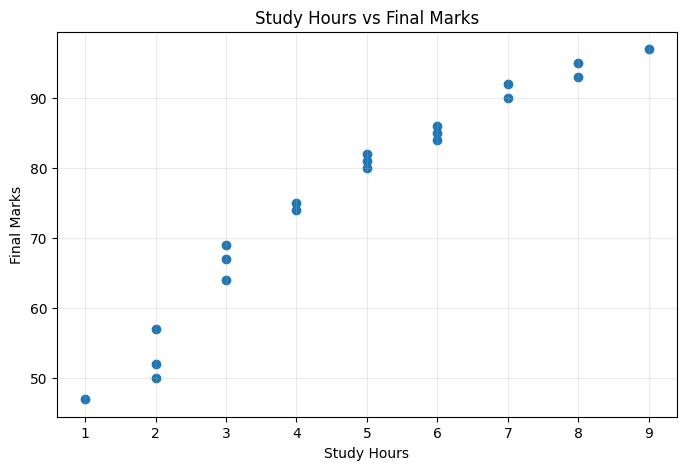

In [20]:
plt.figure(figsize=(8,5))
plt.scatter(df["Study_Hours"], df["Final_Marks"])
plt.xlabel("Study Hours"); plt.ylabel("Final Marks")
plt.title("Study Hours vs Final Marks"); plt.grid(alpha=0.25)
plt.show()

### Day 20 — Plot Attendance vs Final Marks

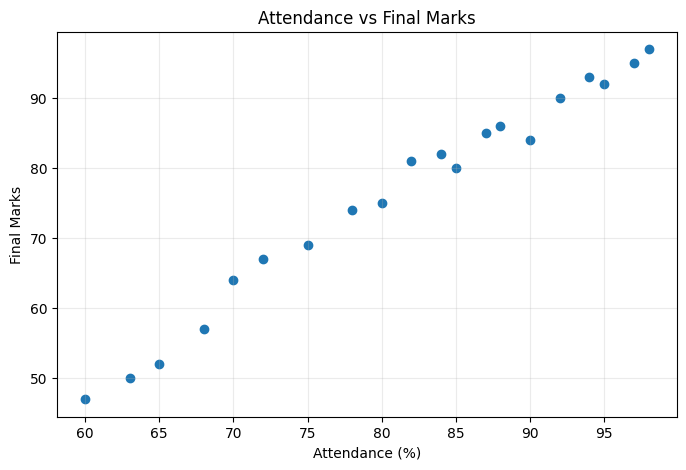

In [21]:
plt.figure(figsize=(8,5))
plt.scatter(df["Attendance"], df["Final_Marks"])
plt.xlabel("Attendance (%)"); plt.ylabel("Final Marks")
plt.title("Attendance vs Final Marks"); plt.grid(alpha=0.25)
plt.show()

### Day 21 — Plot Assignment Score vs Final Marks

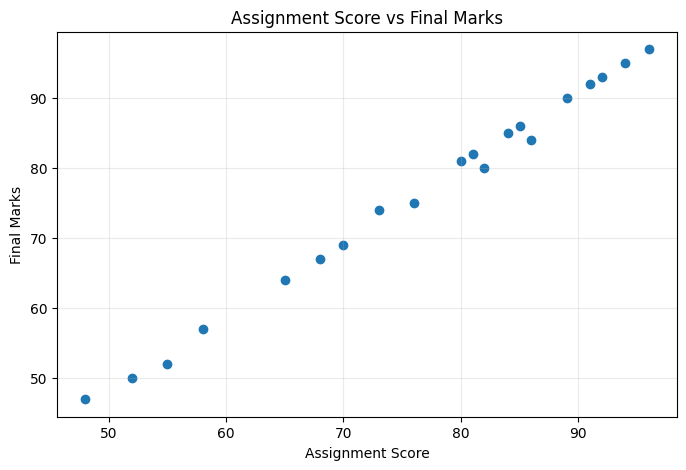

In [22]:
plt.figure(figsize=(8,5))
plt.scatter(df["Assignment_Score"], df["Final_Marks"])
plt.xlabel("Assignment Score"); plt.ylabel("Final Marks")
plt.title("Assignment Score vs Final Marks"); plt.grid(alpha=0.25)
plt.show()

### Day 22 — Review Scatter Plot Comparisons

In [23]:
for title, purpose in {"Study Hours vs Final Marks":"Compare study time with final marks.", "Attendance vs Final Marks":"Compare attendance with final marks.", "Assignment Score vs Final Marks":"Compare assignment results with final marks."}.items(): print(title + ":", purpose)
print("Correlation does not prove causation.")

Study Hours vs Final Marks: Compare study time with final marks.
Attendance vs Final Marks: Compare attendance with final marks.
Assignment Score vs Final Marks: Compare assignment results with final marks.
Correlation does not prove causation.


### Day 23 — Calculate Correlation Matrix

In [24]:
correlation_columns = ["Study_Hours", "Attendance", "Assignment_Score", "Final_Marks"]
correlations = df[correlation_columns].corr()
display(correlations)

,Study_Hours,Attendance,Assignment_Score,Final_Marks
Study_Hours,1.000000,0.980168,0.968473,0.969007
Attendance,0.980168,1.000000,0.993233,0.990679
Assignment_Score,0.968473,0.993233,1.000000,0.997873
Final_Marks,0.969007,0.990679,0.997873,1.000000


### Day 24 — Inspect Final Marks Correlations

In [25]:
final_mark_correlations = correlations["Final_Marks"].sort_values(ascending=False)
display(final_mark_correlations.to_frame("Correlation_with_Final_Marks"))

,Correlation_with_Final_Marks
Final_Marks,1.000000
Assignment_Score,0.997873
Attendance,0.990679
Study_Hours,0.969007


### Day 25 — Create Correlation Heatmap

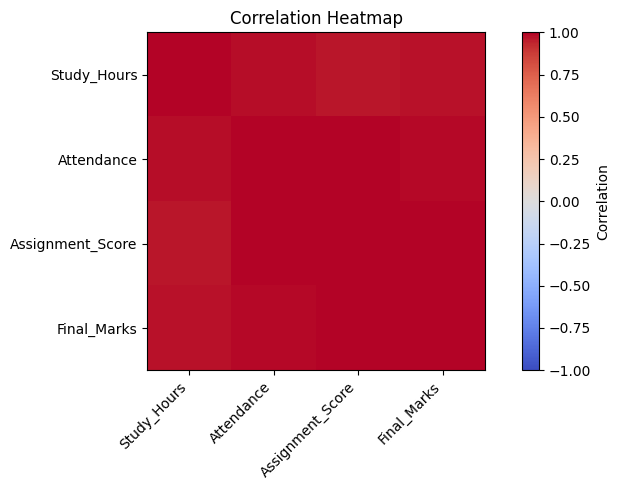

In [26]:
plt.figure(figsize=(8,5))
plt.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(correlations.columns)), correlations.columns, rotation=45, ha="right")
plt.yticks(range(len(correlations.columns)), correlations.columns)
plt.title("Correlation Heatmap"); plt.tight_layout(); plt.show()

### Day 26 — Compare Average Performance Factors

In [27]:
average_values = [df["Study_Hours"].mean(), df["Attendance"].mean(), df["Assignment_Score"].mean(), df["Final_Marks"].mean()]
labels = ["Study Hours", "Attendance", "Assignment Score", "Final Marks"]
average_table = pd.DataFrame({"Performance_Factor": labels, "Average_Value": average_values})
display(average_table)

,Performance_Factor,Average_Value
0,Study Hours,4.80
1,Attendance,81.15
2,Assignment Score,76.25
3,Final Marks,76.00


## Day 26 update summary

**Implemented today:** Compare Average Performance Factors

**Purpose:** Create a table of average values.

Earlier implementation and saved outputs are retained above.